In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings

warnings.filterwarnings(
    "ignore",
    message="KMeans is known to have a memory leak on Windows with MKL.*",
    category=UserWarning
)

In [2]:
df = pd.read_csv(r"E:\BE\Practical\ML_Practical\Practical_6\sales_data_sample.csv", encoding='latin1')

print("Dataset loaded successfully")

Dataset loaded successfully


In [3]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [4]:
df.shape

(2823, 25)

In [5]:
df.dtypes

ORDERNUMBER           int64
QUANTITYORDERED       int64
PRICEEACH           float64
ORDERLINENUMBER       int64
SALES               float64
ORDERDATE            object
STATUS               object
QTR_ID                int64
MONTH_ID              int64
YEAR_ID               int64
PRODUCTLINE          object
MSRP                  int64
PRODUCTCODE          object
CUSTOMERNAME         object
PHONE                object
ADDRESSLINE1         object
ADDRESSLINE2         object
CITY                 object
STATE                object
POSTALCODE           object
COUNTRY              object
TERRITORY            object
CONTACTLASTNAME      object
CONTACTFIRSTNAME     object
DEALSIZE             object
dtype: object

In [6]:
df['ORDERDATE'] = pd.to_datetime(df['ORDERDATE'])

In [7]:
df.dtypes

ORDERNUMBER                  int64
QUANTITYORDERED              int64
PRICEEACH                  float64
ORDERLINENUMBER              int64
SALES                      float64
ORDERDATE           datetime64[ns]
STATUS                      object
QTR_ID                       int64
MONTH_ID                     int64
YEAR_ID                      int64
PRODUCTLINE                 object
MSRP                         int64
PRODUCTCODE                 object
CUSTOMERNAME                object
PHONE                       object
ADDRESSLINE1                object
ADDRESSLINE2                object
CITY                        object
STATE                       object
POSTALCODE                  object
COUNTRY                     object
TERRITORY                   object
CONTACTLASTNAME             object
CONTACTFIRSTNAME            object
DEALSIZE                    object
dtype: object

In [8]:
features = [
    "QUANTITYORDERED",
    "PRICEEACH",
    "SALES"
]

X = df[features].dropna()


In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [10]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

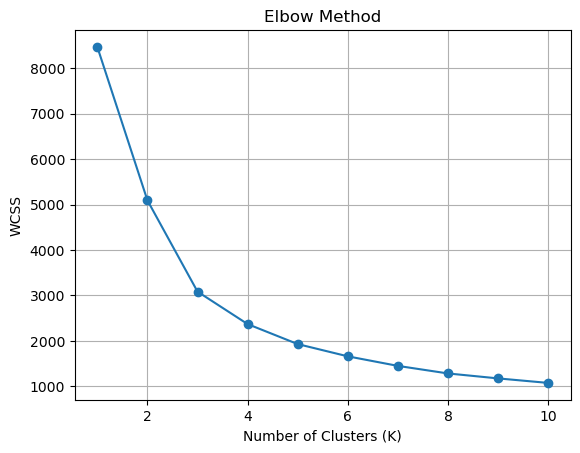

In [11]:
# Elbow Curve to find Optimal K value

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()


In [12]:
k = 3  # Change based on the elbow graph

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X_scaled)
X["KMeans_Cluster"] = kmeans_labels

print("\nK-Means Cluster Counts:")
print(X["KMeans_Cluster"].value_counts().sort_index())


K-Means Cluster Counts:
KMeans_Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


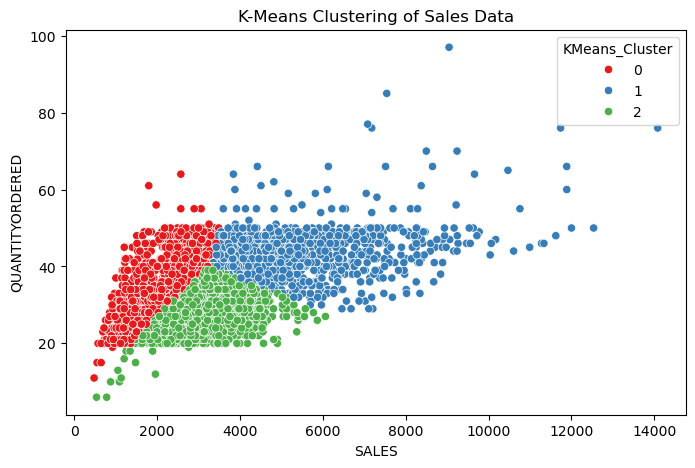

In [13]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=X,
    x="SALES",
    y="QUANTITYORDERED",
    hue="KMeans_Cluster",
    palette="Set1"
)
plt.title("K-Means Clustering of Sales Data")
plt.show()

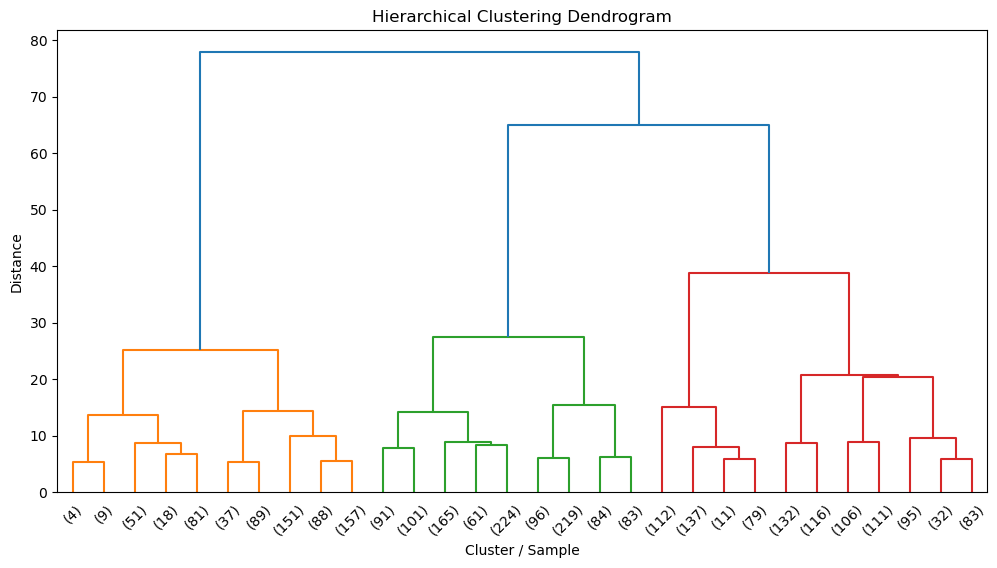

In [14]:
# Plot hierarchical clustering dendrogram
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Cluster / Sample")
plt.ylabel("Distance")
plt.show()

In [15]:
# Apply hierarchical clustering
hierarchical = AgglomerativeClustering(
    n_clusters=k,
    linkage="ward"
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)
X["Hierarchical_Cluster"] = hierarchical_labels

print("\nHierarchical Cluster Counts:")
print(
    X["Hierarchical_Cluster"]
    .value_counts()
    .sort_index()
)


Hierarchical Cluster Counts:
Hierarchical_Cluster
0    1014
1     685
2    1124
Name: count, dtype: int64


In [16]:
print("\nFinal clustered data:")
print(X.head(10))


Final clustered data:
   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster  Hierarchical_Cluster
0               30      95.70  2871.00               2                     2
1               34      81.35  2765.90               2                     2
2               41      94.74  3884.34               1                     1
3               45      83.26  3746.70               1                     0
4               49     100.00  5205.27               1                     1
5               36      96.66  3479.76               2                     2
6               29      86.13  2497.77               2                     2
7               48     100.00  5512.32               1                     1
8               22      98.57  2168.54               2                     2
9               41     100.00  4708.44               1                     1


In [17]:
# Compare average sales across K-Means clusters
print("\nAverage sales by K-Means cluster:")
print(X.groupby("KMeans_Cluster")["SALES"].mean())


Average sales by K-Means cluster:
KMeans_Cluster
0    2009.829955
1    5584.007299
2    3089.153662
Name: SALES, dtype: float64
